# Anomaly detection in network traffic (CICIDS2017, Friday DDoS)
Pipeline: load and sort flows by time, count flows per minute, filter, threshold, evaluate.
Run with **Kernel → Restart and Run All**.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import freqz
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import IsolationForest

DATA_FILE = '../data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv'

## 1. Load the flows and sort by time

In [2]:
df = pd.read_csv(DATA_FILE, encoding='latin1')
df.columns = df.columns.str.strip()
t = pd.to_datetime(df['Timestamp'], format='%m/%d/%Y %H:%M')
t = t.where(t.dt.hour >= 8, t + pd.Timedelta(hours=12))   # afternoon capture: the file has no AM/PM
df['t'] = t
df = df.sort_values('t', kind='stable').reset_index(drop=True)
print(df.shape, df['t'].min(), df['t'].max())

(225745, 86) 2017-07-07 15:30:00 2017-07-07 17:02:00


## 2. Build the per-minute signals x[n] (sampling rate 1/60 Hz)

In [3]:
df['minute'] = df['t'].dt.floor('min')
minutes = pd.date_range(df['minute'].min(), df['minute'].max(), freq='min')
flows = df.groupby('minute').size().reindex(minutes, fill_value=0)
duration = df.groupby('minute')['Flow Duration'].mean().reindex(minutes, fill_value=0)
attack_frac = (df['Label'] != 'BENIGN').groupby(df['minute']).mean().reindex(minutes, fill_value=0)
y = (attack_frac > 0).values            # True for attack minutes
start = int(np.argmax(y))               # first attack minute
print(len(minutes), 'minutes;', y.sum(), 'attack minutes; attack starts at minute', start)

93 minutes; 21 attack minutes; attack starts at minute 26


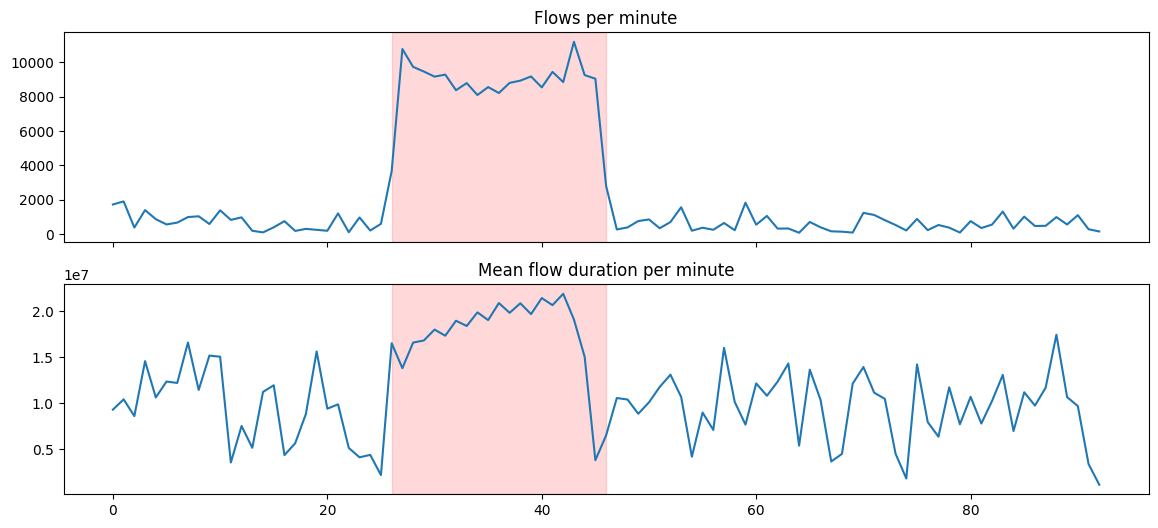

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax[0].plot(flows.values); ax[0].set_title('Flows per minute')
ax[1].plot(duration.values); ax[1].set_title('Mean flow duration per minute')
for a in ax:
    a.fill_between(range(len(y)), 0, 1, where=y, transform=a.get_xaxis_transform(), color='red', alpha=0.15)
plt.show()

## 3. Filter and threshold
Causal moving-average FIR filter, y[n] = (1/N) Σ x[n−k]. Threshold = mean + 3σ of the filtered signal over the normal minutes before the attack.

In [5]:
def causal_ma(x, N):
    return np.convolve(x, np.ones(N) / N)[:len(x)]

def detect(x, N):
    s = causal_ma(x, N)
    base = s[N-1:start]                      # normal minutes only
    thr = base.mean() + 3 * base.std()
    return s, thr, s > thr

x = flows.values.astype(float)
rows = []
for N in [1, 3, 5]:
    s, thr, pred = detect(x, N)
    TP = (pred & y).sum(); FP = (pred & ~y).sum(); FN = (~pred & y).sum()
    p = TP / (TP + FP) if TP + FP else 0
    r = TP / (TP + FN)
    f = 2 * p * r / (p + r) if p + r else 0
    first = int(np.argmax(pred[start:])) if pred[start:].any() else None
    rows.append(dict(N=N, threshold=round(thr), precision=round(p, 3), recall=round(r, 3),
                     f1=round(f, 3), FP=int(FP), FN=int(FN), delay_min=first))
results = pd.DataFrame(rows)
results

,N,threshold,precision,recall,f1,FP,FN,delay_min
0,1,2215,1.000,1.000,1.000,0,0,0
1,3,1601,0.952,0.952,0.952,1,1,1
2,5,1451,0.870,0.952,0.909,3,1,1


## 4. Detected anomalies

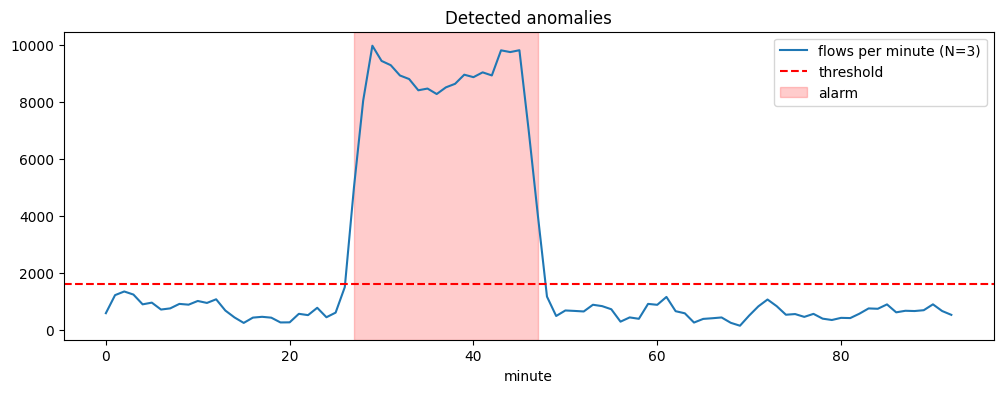

In [6]:
N = 3
s, thr, pred = detect(x, N)
plt.figure(figsize=(12, 4))
ax = plt.gca()
plt.plot(s, label=f'flows per minute (N={N})')
plt.axhline(thr, color='red', linestyle='--', label='threshold')
plt.fill_between(range(len(y)), 0, 1, where=pred, transform=ax.get_xaxis_transform(), color='red', alpha=0.2, label='alarm')
plt.xlabel('minute'); plt.legend(); plt.title('Detected anomalies')
plt.show()

## 5. ROC AUC and Isolation Forest comparison

In [7]:
for name, sig in [('flows per minute', flows.values.astype(float)), ('mean duration per minute', duration.values.astype(float))]:
    for w in [1, 3, 5]:
        sm = np.convolve(sig, np.ones(w) / w, mode='same')
        print(name, 'N =', w, 'AUC', round(roc_auc_score(y, sm), 3))

X = np.column_stack([flows.values, duration.values])
score = -IsolationForest(random_state=0).fit(X).score_samples(X)
print('Isolation Forest AUC', round(roc_auc_score(y, score), 3))

flows per minute N = 1 AUC 1.0
flows per minute N = 3 AUC 1.0
flows per minute N = 5 AUC 1.0
mean duration per minute N = 1 AUC 0.905
mean duration per minute N = 3 AUC 0.907
mean duration per minute N = 5 AUC 0.946
Isolation Forest AUC 0.954


## 6. Filter frequency response and spectrum

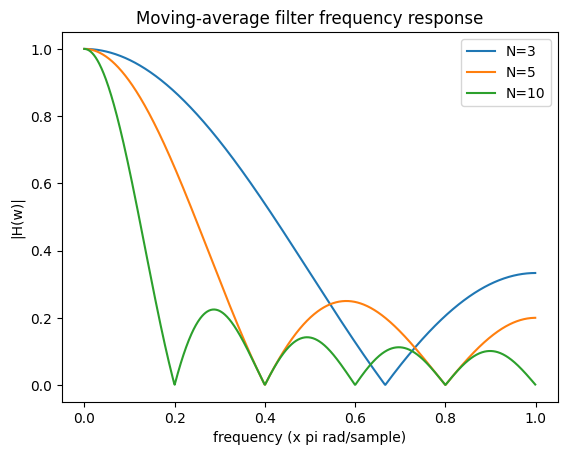

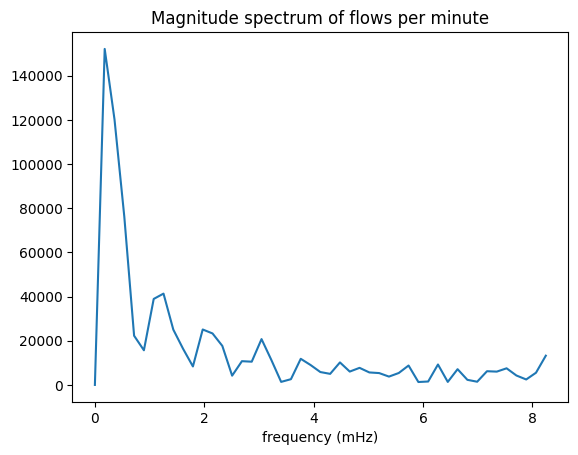

In [8]:
for N in [3, 5, 10]:
    w, h = freqz(np.ones(N) / N, worN=1024)
    plt.plot(w / np.pi, abs(h), label=f'N={N}')
plt.xlabel('frequency (x pi rad/sample)'); plt.ylabel('|H(w)|'); plt.legend()
plt.title('Moving-average filter frequency response'); plt.show()

x0 = x - x.mean()                      # separate copy: x itself stays unchanged
f = np.fft.rfftfreq(len(x0), d=60)
plt.plot(f * 1000, abs(np.fft.rfft(x0)))
plt.xlabel('frequency (mHz)'); plt.title('Magnitude spectrum of flows per minute'); plt.show()